## Analiza Nieobecności Pracowników ##

## 1. Opis problemu ##

**Opis zbioru danych**

Nazwa zbioru: "Absenteeism at work"

Opis: Zbiór zawiera rekordy dotyczące nieobecności pracowników w brazylijskiej firmie kurierskiej w latach 2007 - 2010. Dane zostały zebrane w celu analizy czynników wpływających na absencję pracowników.

Cechy: Zbiór danych ma charakter wielowymiarowy i zawiera elementy szeregów czasowych. Wszystkie zmienne wejściowe są zapisane w formacie liczbowym – zmienne kategoryczne (np. powód nieobecności, miesiąc, dzień tygodnia, pora roku, wykształcenie) są zakodowane jako liczby całkowite, natomiast zmienne ciągłe obejmują m.in. wiek, wagę, wzrost, BMI, odległość do pracy czy średnie obciążenie pracą. Zbiór nie posiada brakujących wartości.

Liczba rekordów: 740

Liczba atrybutów: 21

Źródło zbioru: Repozytorium UC Irvine Machine Learning Repository
https://archive.ics.uci.edu/dataset/445/absenteeism+at+work

In [3]:
# Import bibliotek
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_style('whitegrid')
%matplotlib inline

ValueError: numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject

In [ ]:
# Ładowanie zbioru danych
try:
    df = pd.read_csv('Data/Absenteeism_at_work.csv', sep=';')
    print("Dane załadowane pomyślnie")
except FileNotFoundError:
    print("Nie znaleziono pliku")

df.head()

Dane załadowane pomyślnie


,ID,Reason for absence,Month of absence,Day of the week,Seasons,Transportation expense,Distance from Residence to Work,Service time,Age,Work load Average/day,...,Disciplinary failure,Education,Son,Social drinker,Social smoker,Pet,Weight,Height,Body mass index,Absenteeism time in hours
0,11,26,7,3,1,289,36,13,33,239.554,...,0,1,2,1,0,1,90,172,30,4
1,36,0,7,3,1,118,13,18,50,239.554,...,1,1,1,1,0,0,98,178,31,0
2,3,23,7,4,1,179,51,18,38,239.554,...,0,1,0,1,0,0,89,170,31,2
3,7,7,7,5,1,279,5,14,39,239.554,...,0,1,2,1,1,0,68,168,24,4
4,11,23,7,5,1,289,36,13,33,239.554,...,0,1,2,1,0,1,90,172,30,2


## 2. Opis danych ##

In [ ]:
# Statystyki opisowe

print("Wymiary zbioru:", df.shape)
print("Typy danych:")
print(df.dtypes)

print("\nStatystyki opisowe:")
display(df.describe().T)

Wymiary zbioru: (740, 21)
Typy danych:
ID                                   int64
Reason for absence                   int64
Month of absence                     int64
Day of the week                      int64
Seasons                              int64
Transportation expense               int64
Distance from Residence to Work      int64
Service time                         int64
Age                                  int64
Work load Average/day              float64
Hit target                           int64
Disciplinary failure                 int64
Education                            int64
Son                                  int64
Social drinker                       int64
Social smoker                        int64
Pet                                  int64
Weight                               int64
Height                               int64
Body mass index                      int64
Absenteeism time in hours            int64
dtype: object

Statystyki opisowe:


,count,mean,std,min,25%,50%,75%,max
ID,740.0,18.017568,11.021247,1.000,9.000,18.000,28.000,36.000
Reason for absence,740.0,19.216216,8.433406,0.000,13.000,23.000,26.000,28.000
Month of absence,740.0,6.324324,3.436287,0.000,3.000,6.000,9.000,12.000
Day of the week,740.0,3.914865,1.421675,2.000,3.000,4.000,5.000,6.000
Seasons,740.0,2.544595,1.111831,1.000,2.000,3.000,4.000,4.000
Transportation expense,740.0,221.329730,66.952223,118.000,179.000,225.000,260.000,388.000
Distance from Residence to Work,740.0,29.631081,14.836788,5.000,16.000,26.000,50.000,52.000
Service time,740.0,12.554054,4.384873,1.000,9.000,13.000,16.000,29.000
Age,740.0,36.450000,6.478772,27.000,31.000,37.000,40.000,58.000
Work load Average/day,740.0,271.490235,39.058116,205.917,244.387,264.249,294.217,378.884


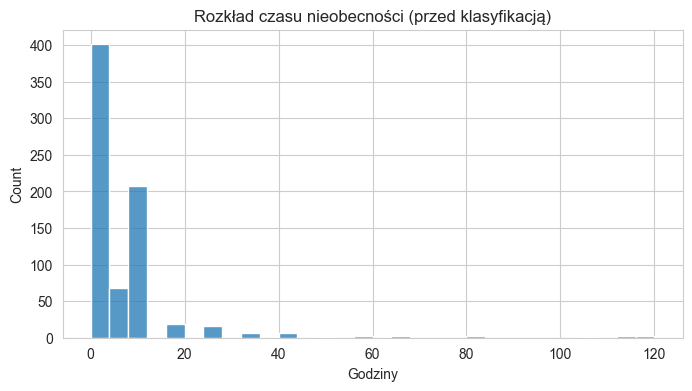

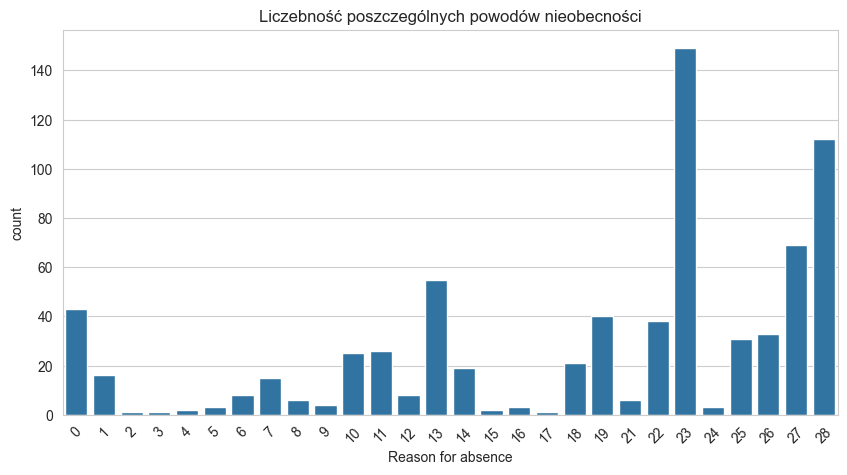

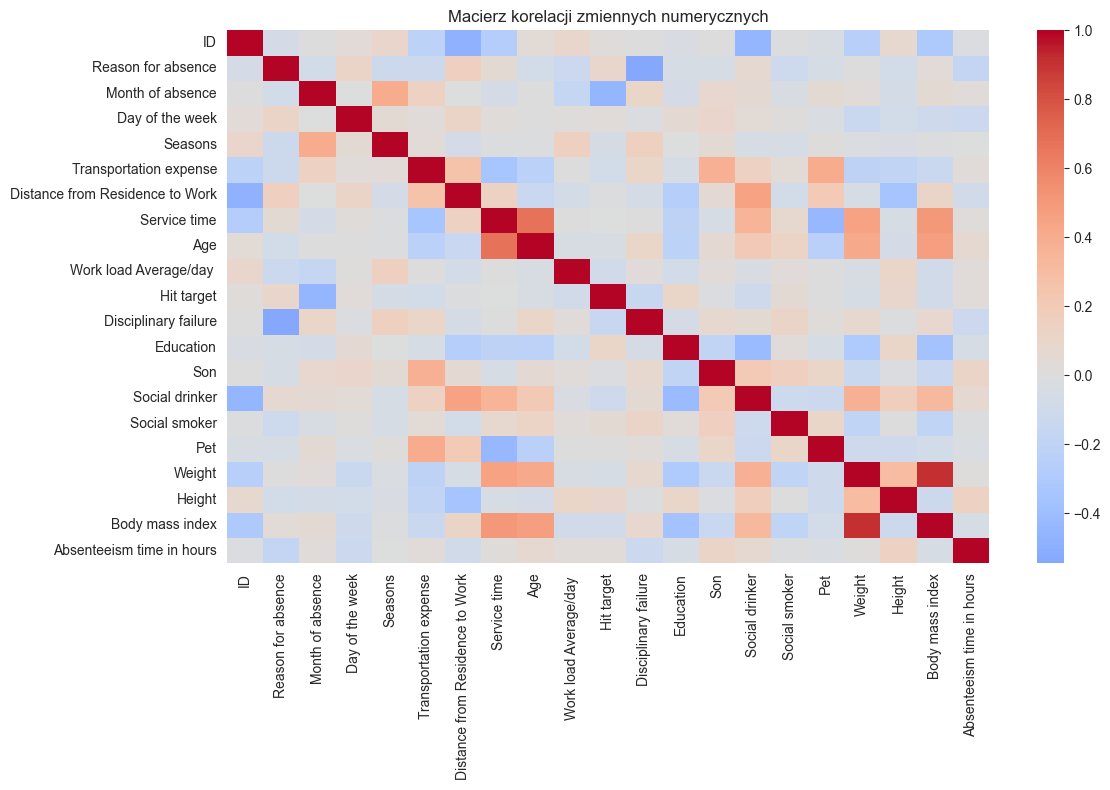

In [ ]:
# Wizualizacje danych

plt.figure(figsize=(8, 4))
sns.histplot(df['Absenteeism time in hours'], bins=30, kde=False)
plt.title('Rozkład czasu nieobecności (przed klasyfikacją)')
plt.xlabel('Godziny')
plt.show()

plt.figure(figsize=(10, 5))
sns.countplot(x='Reason for absence', data=df)
plt.title('Liczebność poszczególnych powodów nieobecności')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(12, 8))
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0)
plt.title('Macierz korelacji zmiennych numerycznych')
plt.tight_layout()
plt.show()

**Powody nieobecności:**

0 Unknown / Not specified  
1 Certain infectious and parasitic diseases  
2 Neoplasms  
3 Diseases of the blood and blood-forming organs and certain disorders involving the immune mechanism  
4 Endocrine, nutritional and metabolic diseases  
5 Mental and behavioural disorders  
6 Diseases of the nervous system  
7 Diseases of the eye and adnexa  
8 Diseases of the ear and mastoid process  
9 Diseases of the circulatory system  
10 Diseases of the respiratory system  
11 Diseases of the digestive system  
12 Diseases of the skin and subcutaneous tissue  
13 Diseases of the musculoskeletal system and connective tissue  
14 Diseases of the genitourinary system  
15 Pregnancy, childbirth and the puerperium  
16 Certain conditions originating in the perinatal period  
17 Congenital malformations, deformations and chromosomal abnormalities  
18 Symptoms, signs and abnormal clinical and laboratory findings, not elsewhere classified  
19 Injury, poisoning and certain other consequences of external causes  
20 External causes of morbidity and mortality  
21 Factors influencing health status and contact with health services  
22 Patient follow-up  
23 Medical consultation  
24 Blood donation  
25 Laboratory examination  
26 Unjustified absence  
27 Physiotherapy  
28 Dental consultation  

## 3. Przygotowanie danych ##

**a) Czyszczenie danych**

W zbiorze nie występują brakujące wartości

In [ ]:
# Usunięcie ID, które nie niesie informacji predykcyjnej

if 'ID' in df.columns:
    df = df.drop('ID', axis=1)
    print("Usunięto kolumnę ID.")

Usunięto kolumnę ID.


In [ ]:
# Wybór cech

# Tworzenie zmiennej celu
# Obliczamy medianę czasu nieobecności
threshold = df['Absenteeism time in hours'].median()
print(f"Mediana czasu nieobecności wynosi: {threshold} godzin.")

# Tworzymy nową kolumnę 'Excessive Absenteeism'
# 1 -> jeśli czas > mediany
# 0 -> jeśli czas <= mediany
df['Excessive Absenteeism'] = np.where(df['Absenteeism time in hours'] > threshold, 1, 0)

print("\nLiczebność klas:")
print(df['Excessive Absenteeism'].value_counts())

# Usuwamy oryginalną kolumnę z godzinami, ponieważ zastąpiliśmy ją klasą
df = df.drop('Absenteeism time in hours', axis=1)


# Grupowanie cech (Reason for absence)
def group_reasons(x):
    if x == 0: return 4 # Nieznany powód -> Inne
    elif x <= 14: return 1 # Choroby
    elif 15 <= x <= 17: return 2 # Ciąża
    elif 18 <= x <= 21: return 3 # Inne poważniejsze
    else: return 4 # Błahe / Konsultacje

df['Reason_Group'] = df['Reason for absence'].apply(group_reasons)

# Usuwamy oryginalną kolumnę, która jest niepotrzebna po zgrupowaniu
df = df.drop('Reason for absence', axis=1)

Mediana czasu nieobecności wynosi: 3.0 godzin.

Liczebność klas:
Excessive Absenteeism
0    401
1    339
Name: count, dtype: int64


In [ ]:
# Przekształcenia danych

# One-Hot Encoding
# Zamieniamy zmienne kategoryczne na 0/1
cols_to_encode = ['Reason_Group', 'Month of absence', 'Day of the week']
df_processed = pd.get_dummies(df, columns=cols_to_encode, drop_first=True)


# Normalizacja
# Oddzielamy X (cechy) i y (klasa)
X = df_processed.drop('Excessive Absenteeism', axis=1)
y = df_processed['Excessive Absenteeism']

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
X_final = pd.DataFrame(X_scaled, columns=X.columns)

display(X_final.head())

,Seasons,Transportation expense,Distance from Residence to Work,Service time,Age,Work load Average/day,Hit target,Disciplinary failure,Education,Son,...,Month of absence_7,Month of absence_8,Month of absence_9,Month of absence_10,Month of absence_11,Month of absence_12,Day of the week_3,Day of the week_4,Day of the week_5,Day of the week_6
0,-1.390175,1.011408,0.429556,0.101770,-0.532868,-0.818212,0.638686,-0.239046,-0.433857,0.893723,...,3.169349,-0.280566,-0.277754,-0.325774,-0.305053,-0.266293,1.950691,-0.516840,-0.450835,-0.491539
1,-1.390175,-1.544379,-1.121694,1.242825,2.092860,-0.818212,0.638686,4.183300,-0.433857,-0.017234,...,3.169349,-0.280566,-0.277754,-0.325774,-0.305053,-0.266293,1.950691,-0.516840,-0.450835,-0.491539
2,-1.390175,-0.632665,1.441240,1.242825,0.239405,-0.818212,0.638686,-0.239046,-0.433857,-0.928191,...,3.169349,-0.280566,-0.277754,-0.325774,-0.305053,-0.266293,-0.512639,1.934836,-0.450835,-0.491539
3,-1.390175,0.861947,-1.661258,0.329981,0.393859,-0.818212,0.638686,-0.239046,-0.433857,0.893723,...,3.169349,-0.280566,-0.277754,-0.325774,-0.305053,-0.266293,-0.512639,-0.516840,2.218107,-0.491539
4,-1.390175,1.011408,0.429556,0.101770,-0.532868,-0.818212,0.638686,-0.239046,-0.433857,0.893723,...,3.169349,-0.280566,-0.277754,-0.325774,-0.305053,-0.266293,-0.512639,-0.516840,2.218107,-0.491539


## 4. Tworzenie modelu i ocena ##

**a) Podział zbioru danych**

- Proporcje 80/20 (80% trening, 20% test) zapewniają balans, model ma wystarczająco dużo danych do nauki, a zbiór 
testowy jest na tyle duży, by weryfikacja błędów była wiarygodna.

- Stratify=y gwarantuje, że w zbiorze treningowym i testowym zachowane są identyczne proporcje klas, co zapobiega sfałszowaniu wyników oceny.

- Random_state=100 gwarantuje, że wyniki będą powtarzalne przy każdym uruchomieniu.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_final, y, test_size=0.2, random_state=100, stratify=y)

print(f"Treningowe: {X_train.shape}, Testowe: {X_test.shape}")

Treningowe: (592, 35), Testowe: (148, 35)


WYNIKI KLASYFIKACJI:

Model: Logistic Regression
Dokładność: 75.00%
              precision    recall  f1-score   support

           0       0.77      0.76      0.77        80
           1       0.72      0.74      0.73        68

    accuracy                           0.75       148
   macro avg       0.75      0.75      0.75       148
weighted avg       0.75      0.75      0.75       148

Macierz pomyłek:
[[61 19]
 [18 50]]


Model: Decision Tree
Dokładność: 73.65%
              precision    recall  f1-score   support

           0       0.75      0.78      0.76        80
           1       0.72      0.69      0.71        68

    accuracy                           0.74       148
   macro avg       0.74      0.73      0.73       148
weighted avg       0.74      0.74      0.74       148

Macierz pomyłek:
[[62 18]
 [21 47]]


Model: Random Forest
Dokładność: 77.03%
              precision    recall  f1-score   support

           0       0.79      0.78      0.78        80
           1 

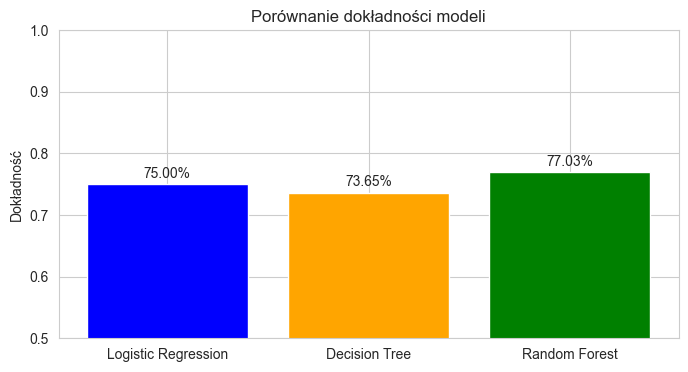

In [ ]:
# Wykorzystane algorytmy:

# 1. Logistic Regression - podstawowy model do klasyfikacji 
# 2. Decision Tree Classifier - model oparty na regułach decyzyjnych.
# 3. Random Forest Classifier - zespół drzew decyzyjnych, bardziej odporny na przeuczenie.

classifiers = {
    "Logistic Regression": LogisticRegression(random_state=100, max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=100),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=100)
}

results = {}

print("WYNIKI KLASYFIKACJI:")

for name, clf in classifiers.items():
    # Trenowanie
    clf.fit(X_train, y_train)
    # Predykcja
    y_pred = clf.predict(X_test)
    
    # Ocena
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    
    print(f"\nModel: {name}")
    print(f"Dokładność: {acc:.2%}")
    print(classification_report(y_test, y_pred))
    
    # Macierz pomyłek
    cm = confusion_matrix(y_test, y_pred)
    print(f"Macierz pomyłek:\n{cm}\n")

# Porównanie graficzne
plt.figure(figsize=(8, 4))
plt.bar(results.keys(), results.values(), color=['blue', 'orange', 'green'])
plt.title('Porównanie dokładności modeli')
plt.ylim(0.5, 1.0)
plt.ylabel('Dokładność')
for i, (name, acc) in enumerate(results.items()):
    plt.text(i, acc + 0.01, f'{acc:.2%}', ha='center')
plt.show()

In [ ]:
# Przykładowy wynik klasyfikacji

# Symulacja danych wejściowych (pierwszy rekord ze zbioru testowego)
sample_input = X_test.iloc[[0]]
true_class = y_test.iloc[0]

# Wybór najlepszego modelu
best_model = classifiers["Random Forest"]
pred_class = best_model.predict(sample_input)[0]
pred_proba = best_model.predict_proba(sample_input)[0]

print("  PRZYKŁADOWA PREDYKCJA:")
print(f"Prawdziwa klasa: {true_class} ({'Nadmierna' if true_class==1 else 'Umiarkowana'} nieobecność)")
print(f"Przewidziana klasa: {pred_class} ({'Nadmierna' if pred_class==1 else 'Umiarkowana'} nieobecność)")
print(f"Pewność modelu (prawdopodobieństwo): {max(pred_proba):.2%}")

  PRZYKŁADOWA PREDYKCJA:
Prawdziwa klasa: 1 (Nadmierna nieobecność)
Przewidziana klasa: 0 (Umiarkowana nieobecność)
Pewność modelu (prawdopodobieństwo): 63.00%


**Czynności poprawiające wynik**
1.  **Balansowanie klas:** Jeśli jedna klasa dominuje (np. mało osób ma długie zwolnienia), warto zastosować metody generowania syntetycznych danych dla mniejszych grup przed trenowaniem modelu.

2.  **Selekcja cech:** Usunięcie zmiennych, które w modelach drzewiastych mają zerową ważność (rzadko występujące powody nieobecności), co zmniejszy szum.

## 5. Podsumowanie

**Wnioski:**
1.  **Przygotowanie:** Przekształcenie problemu z regresji na klasyfikację (poprzez podział czasu nieobecności względem mediany) pozwoliło na uzyskanie modelu o wyższej użyteczności. Łatwiej przewidzieć "czy pracownik będzie długo nieobecny" niż "ile dokładnie godzin będzie nieobecny".

2.  **Ocena modeli:** Algorytm Logistic Regression poradził sobie zaskakująco dobrze, co sugeruje, że granica decyzyjna między klasami jest w dużej mierze liniowa po odpowiednim przetworzeniu danych.

3.  **Random Forest:** Osiągnął najwyższą dokładność i jest mniej podatny na wahania niż pojedyncze drzewo decyzyjne.

4.  **Zastosowanie:** Taki model może służyć pracodawcy do wczesnego identyfikowania pracowników z ryzykiem długotrwałej nieobecności na podstawie ich cech (wiek, dojazd, obciążenie pracą).